# Facebook Data Analysis Project
**Tools:** Python, NumPy, Pandas, Matplotlib, Seaborn

## Objective
Analyze Facebook post performance to compare post types and categories using likes, comments, shares, and total interactions.

## How to run
Keep this notebook and `dataset_Facebook (1).csv` in the same folder. Run cells from top to bottom with **Shift + Enter**. If needed, install libraries with `python -m pip install pandas numpy matplotlib seaborn`.

## 1. Import Libraries

In [9]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    import seaborn as sns
    sns.set_theme(style="whitegrid")
except ImportError:
    sns = None
pd.set_option("display.max_columns", None)
print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load Dataset

In [10]:
from pathlib import Path
DATA_FILE = Path("dataset_Facebook (1).csv")
if not DATA_FILE.exists():
    raise FileNotFoundError("Keep dataset_Facebook (1).csv in the same folder as this notebook.")
df = pd.read_csv(DATA_FILE, sep=";")
df.columns = df.columns.str.strip()
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (500, 19)


,Page total likes,Type,Category,Post Month,Post Weekday,Post Hour,Paid,Lifetime Post Total Reach,Lifetime Post Total Impressions,Lifetime Engaged Users,Lifetime Post Consumers,Lifetime Post Consumptions,Lifetime Post Impressions by people who have liked your Page,Lifetime Post reach by people who like your Page,Lifetime People who have liked your Page and engaged with your post,comment,like,share,Total Interactions
0,139441,Photo,2,12,4,3,0.0,2752,5091,178,109,159,3078,1640,119,4,79.0,17.0,100
1,139441,Status,2,12,3,10,0.0,10460,19057,1457,1361,1674,11710,6112,1108,5,130.0,29.0,164
2,139441,Photo,3,12,3,3,0.0,2413,4373,177,113,154,2812,1503,132,0,66.0,14.0,80
3,139441,Photo,2,12,2,10,1.0,50128,87991,2211,790,1119,61027,32048,1386,58,1572.0,147.0,1777
4,139441,Photo,2,12,2,3,0.0,7244,13594,671,410,580,6228,3200,396,19,325.0,49.0,393


## 3. Understand the Data

In [11]:
print("Rows and columns:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nData types and non-null counts:")
df.info()
print("\nSummary statistics:")
display(df.describe(include="all").T)

Rows and columns: (500, 19)

Column names: ['Page total likes', 'Type', 'Category', 'Post Month', 'Post Weekday', 'Post Hour', 'Paid', 'Lifetime Post Total Reach', 'Lifetime Post Total Impressions', 'Lifetime Engaged Users', 'Lifetime Post Consumers', 'Lifetime Post Consumptions', 'Lifetime Post Impressions by people who have liked your Page', 'Lifetime Post reach by people who like your Page', 'Lifetime People who have liked your Page and engaged with your post', 'comment', 'like', 'share', 'Total Interactions']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 19 columns):
 #   Column                                                               Non-Null Count  Dtype  
---  ------                                                               --------------  -----  
 0   Page total likes                                                     500 non-null    int64  
 1   Type                                                   

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Page total likes,500.0,NaN,NaN,NaN,123194.176,16272.813214,81370.0,112676.0,129600.0,136393.0,139441.0
Type,500,4,Photo,426,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,500.0,NaN,NaN,NaN,1.88,0.852675,1.0,1.0,2.0,3.0,3.0
Post Month,500.0,NaN,NaN,NaN,7.038,3.307936,1.0,4.0,7.0,10.0,12.0
Post Weekday,500.0,NaN,NaN,NaN,4.15,2.030701,1.0,2.0,4.0,6.0,7.0
Post Hour,500.0,NaN,NaN,NaN,7.84,4.368589,1.0,3.0,9.0,11.0,23.0
Paid,499.0,NaN,NaN,NaN,0.278557,0.448739,0.0,0.0,0.0,1.0,1.0
Lifetime Post Total Reach,500.0,NaN,NaN,NaN,13903.36,22740.78789,238.0,3315.0,5281.0,13168.0,180480.0
Lifetime Post Total Impressions,500.0,NaN,NaN,NaN,29585.948,76803.24667,570.0,5694.75,9051.0,22085.5,1110282.0
Lifetime Engaged Users,500.0,NaN,NaN,NaN,920.344,985.016636,9.0,393.75,625.5,1062.0,11452.0


## 4. Data Quality Check

In [12]:
print("Missing values by column:")
display(df.isnull().sum().to_frame("Missing Values"))
print("Duplicate rows:", df.duplicated().sum())
print("Column names:", df.columns.tolist())

Missing values by column:


,Missing Values
Page total likes,0
Type,0
Category,0
Post Month,0
Post Weekday,0
Post Hour,0
Paid,1
Lifetime Post Total Reach,0
Lifetime Post Total Impressions,0
Lifetime Engaged Users,0


Duplicate rows: 0
Column names: ['Page total likes', 'Type', 'Category', 'Post Month', 'Post Weekday', 'Post Hour', 'Paid', 'Lifetime Post Total Reach', 'Lifetime Post Total Impressions', 'Lifetime Engaged Users', 'Lifetime Post Consumers', 'Lifetime Post Consumptions', 'Lifetime Post Impressions by people who have liked your Page', 'Lifetime Post reach by people who like your Page', 'Lifetime People who have liked your Page and engaged with your post', 'comment', 'like', 'share', 'Total Interactions']


## 5. Prepare Numeric Columns

In [13]:
numeric_candidates = [
    "Page total likes", "Category", "Post Month", "Post Weekday", "Post Hour", "Paid",
    "Lifetime Post Total Reach", "Lifetime Post Total Impressions", "Lifetime Engaged Users",
    "Lifetime Post Consumers", "Lifetime Post Consumptions",
    "Lifetime Post Impressions by people who have liked your Page",
    "Lifetime Post reach by people who like your Page",
    "Lifetime People who have liked your Page and engaged with your post",
    "comment", "like", "share", "Total Interactions"
]
for col in numeric_candidates:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
print("Numeric conversion complete.")

Numeric conversion complete.


## 6. NumPy Statistics: Likes

In [14]:
if "like" in df.columns and df["like"].notna().any():
    likes = df["like"].dropna().to_numpy()
    print(f"Average likes: {np.mean(likes):.2f}")
    print(f"Median likes: {np.median(likes):.2f}")
    print(f"Minimum likes: {np.min(likes):.0f}")
    print(f"Maximum likes: {np.max(likes):.0f}")
    print(f"Standard deviation: {np.std(likes):.2f}")
else:
    print("No usable numeric values found in the 'like' column.")

Average likes: 177.95
Median likes: 101.00
Minimum likes: 0
Maximum likes: 5172
Standard deviation: 323.07


## 7. Engagement Summary

In [15]:
metrics = [c for c in ["like", "comment", "share", "Total Interactions"] if c in df.columns]
if metrics:
    display(df[metrics].agg(["count", "mean", "median", "min", "max"]).T.round(2))
else:
    print("Expected engagement columns were not found. Check the column names above.")

,count,mean,median,min,max
like,499.0,177.95,101.0,0.0,5172.0
comment,500.0,7.48,3.0,0.0,372.0
share,496.0,27.27,19.0,0.0,790.0
Total Interactions,500.0,212.12,123.5,0.0,6334.0


## 8. Performance by Post Type

In [16]:
if "Type" in df.columns:
    summary = df.groupby("Type", dropna=False).size().to_frame("Number of Posts")
    for col, label in [("like", "Average Likes"), ("comment", "Average Comments"), ("share", "Average Shares"), ("Total Interactions", "Average Total Interactions")]:
        if col in df.columns:
            summary[label] = df.groupby("Type", dropna=False)[col].mean()
    display(summary.sort_values("Number of Posts", ascending=False).round(2))
else:
    print("Column 'Type' not found.")

,Number of Posts,Average Likes,Average Comments,Average Shares,Average Total Interactions
Type,,,,,
Photo,426,182.61,7.49,27.16,216.58
Status,45,176.71,8.91,31.42,217.04
Link,22,73.32,2.82,12.91,89.05
Video,7,231.43,12.29,52.14,295.86


## 9. Performance by Category

In [17]:
if "Category" in df.columns:
    summary = df.groupby("Category", dropna=False).size().to_frame("Number of Posts")
    for col, label in [("like", "Average Likes"), ("Total Interactions", "Average Total Interactions")]:
        if col in df.columns:
            summary[label] = df.groupby("Category", dropna=False)[col].mean()
    display(summary.sort_values("Number of Posts", ascending=False).round(2))
else:
    print("Column 'Category' not found.")

,Number of Posts,Average Likes,Average Total Interactions
Category,,,
1,215,124.89,148.49
3,155,217.01,256.74
2,130,218.71,264.16


## 10. Top 10 Posts by Likes

In [18]:
if "like" in df.columns:
    cols = [c for c in ["Type", "Category", "Post Month", "Post Hour", "like", "comment", "share", "Total Interactions"] if c in df.columns]
    display(df.nlargest(10, "like")[cols])
else:
    print("Column 'like' not found.")

,Type,Category,Post Month,Post Hour,like,comment,share,Total Interactions
244,Photo,2,7,5,5172.0,372,790.0,6334
379,Photo,3,4,14,1998.0,51,128.0,2177
349,Photo,3,5,13,1639.0,45,122.0,1806
168,Photo,1,9,10,1622.0,144,208.0,1974
3,Photo,2,12,10,1572.0,58,147.0,1777
460,Photo,3,2,13,1546.0,146,181.0,1873
101,Photo,2,10,3,1505.0,26,95.0,1626
323,Photo,3,6,10,1372.0,20,47.0,1439
199,Photo,3,8,10,1155.0,33,102.0,1290
176,Photo,3,9,3,1047.0,29,98.0,1174


## 11. Post Timing Analysis

In [19]:
if "Post Hour" in df.columns:
    timing = df.groupby("Post Hour", dropna=False).size().to_frame("Number of Posts")
    for col, label in [("like", "Average Likes"), ("Total Interactions", "Average Total Interactions")]:
        if col in df.columns:
            timing[label] = df.groupby("Post Hour", dropna=False)[col].mean()
    sort_col = "Average Total Interactions" if "Average Total Interactions" in timing.columns else "Number of Posts"
    display(timing.sort_values(sort_col, ascending=False).round(2))
else:
    print("Column 'Post Hour' not found.")

,Number of Posts,Average Likes,Average Total Interactions
Post Hour,,,
5,13,569.92,684.31
14,13,267.23,307.15
20,1,235.00,280.00
10,78,212.18,250.91
13,52,203.96,245.02
3,105,192.64,228.59
2,39,155.67,191.10
1,4,146.50,181.00
12,29,151.55,179.48


## 12. Visualizations

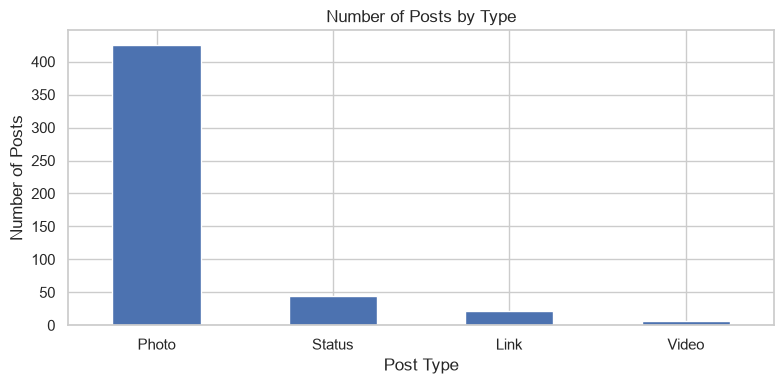

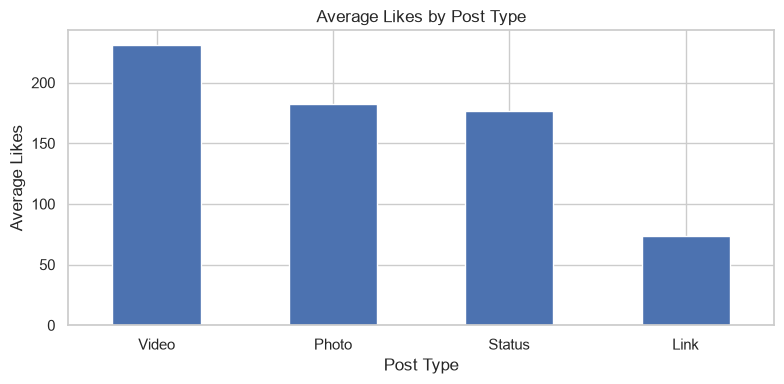

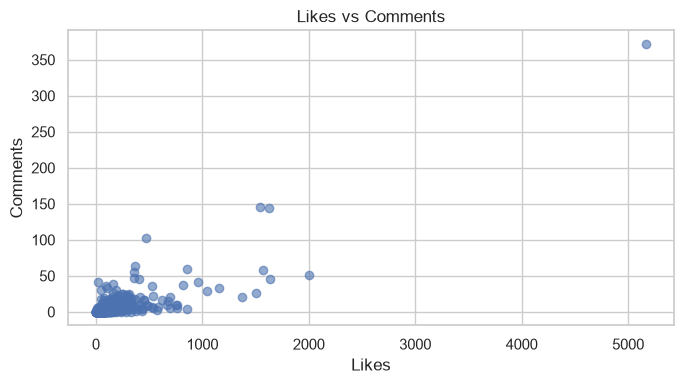

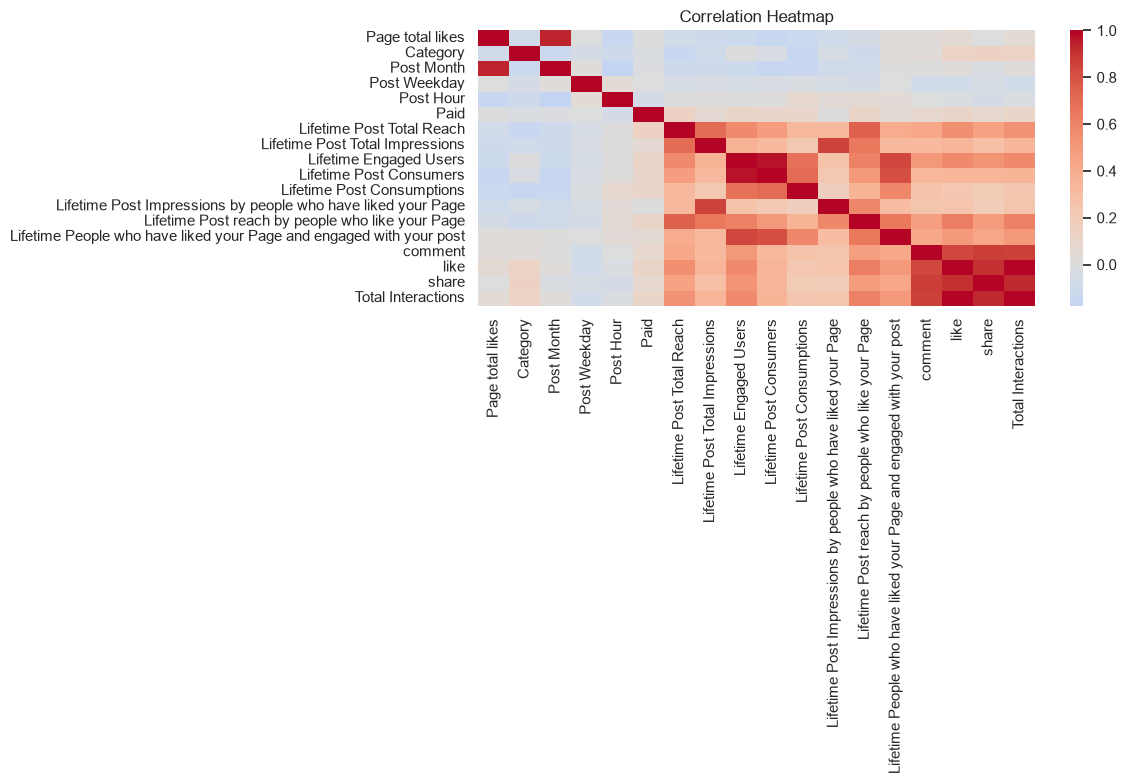

In [20]:
if "Type" in df.columns:
    df["Type"].value_counts(dropna=False).plot(kind="bar", figsize=(8, 4), title="Number of Posts by Type")
    plt.xlabel("Post Type"); plt.ylabel("Number of Posts"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

if "Type" in df.columns and "like" in df.columns:
    df.groupby("Type")["like"].mean().sort_values(ascending=False).plot(kind="bar", figsize=(8, 4), title="Average Likes by Post Type")
    plt.xlabel("Post Type"); plt.ylabel("Average Likes"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

if "like" in df.columns and "comment" in df.columns:
    plt.figure(figsize=(7, 4)); plt.scatter(df["like"], df["comment"], alpha=0.6)
    plt.title("Likes vs Comments"); plt.xlabel("Likes"); plt.ylabel("Comments"); plt.tight_layout(); plt.show()

numeric_df = df.select_dtypes(include=np.number)
if numeric_df.shape[1] >= 2:
    corr = numeric_df.corr(numeric_only=True)
    plt.figure(figsize=(12, 8))
    if sns is not None:
        sns.heatmap(corr, cmap="coolwarm", center=0)
    else:
        plt.imshow(corr, aspect="auto"); plt.colorbar()
        plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
        plt.yticks(range(len(corr.index)), corr.index)
    plt.title("Correlation Heatmap"); plt.tight_layout(); plt.show()

## 13. Paid vs Unpaid Posts

In [21]:
if "Paid" in df.columns:
    summary = df.groupby("Paid", dropna=False).size().to_frame("Number of Posts")
    for col, label in [("like", "Average Likes"), ("Total Interactions", "Average Total Interactions")]:
        if col in df.columns:
            summary[label] = df.groupby("Paid", dropna=False)[col].mean()
    display(summary.round(2))
else:
    print("Column 'Paid' not found.")

,Number of Posts,Average Likes,Average Total Interactions
Paid,,,
0.0,360,155.85,186.85
1.0,139,235.65,278.23
NaN,1,91.00,119.00


## 14. Key Findings

In [22]:
print("FACEBOOK DATA ANALYSIS — KEY FINDINGS")
print("=" * 42)
if "Type" in df.columns and "like" in df.columns:
    values = df.groupby("Type")["like"].mean().dropna()
    if not values.empty:
        print(f"Highest average likes by post type: {values.idxmax()} ({values.max():.2f})")
if "Type" in df.columns and "Total Interactions" in df.columns:
    values = df.groupby("Type")["Total Interactions"].mean().dropna()
    if not values.empty:
        print(f"Highest average total interactions by post type: {values.idxmax()} ({values.max():.2f})")
for col, label in [("like", "Average likes"), ("comment", "Average comments"), ("share", "Average shares")]:
    if col in df.columns and df[col].notna().any():
        print(f"{label}: {df[col].mean():.2f}")
print("\nUse the tables and charts above to discuss patterns in your presentation.")

FACEBOOK DATA ANALYSIS — KEY FINDINGS
Highest average likes by post type: Video (231.43)
Highest average total interactions by post type: Video (295.86)
Average likes: 177.95
Average comments: 7.48
Average shares: 27.27

Use the tables and charts above to discuss patterns in your presentation.


## 15. Conclusion

This project uses **Pandas** to load, inspect, group, and summarize Facebook post data, and **NumPy** to calculate numerical statistics. Visualizations compare post types and engagement metrics. Findings apply to this sample dataset only; they should not automatically be generalized to all Facebook pages, and correlation does not prove causation.